# Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/processed/telco_customer_churn_clean.csv")

print("Shape:", df.shape)

Shape: (7043, 21)


In [2]:
churn_rate = (
    df["Churn"]
    .eq("Yes")
    .mean() * 100
)

print(f"Overall churn rate: {churn_rate:.2f}%")

Overall churn rate: 26.54%


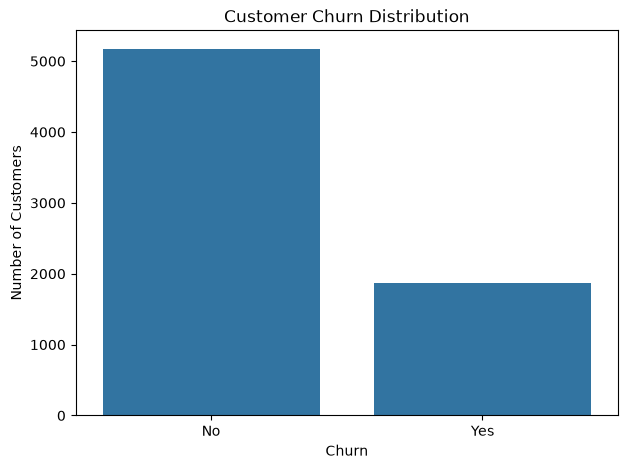

In [3]:
# CHurn DIstribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [4]:
churn_pct = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(churn_pct)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### Churn by COntract

In [5]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


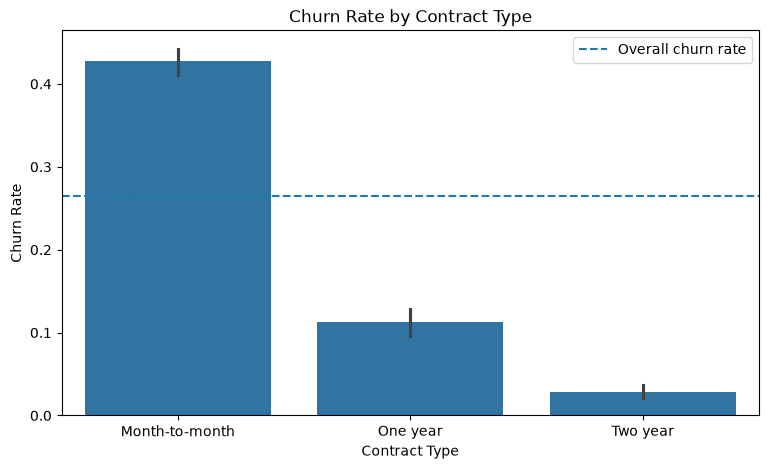

In [6]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Contract",
    y=df["Churn"].eq("Yes").astype(int)
)

plt.axhline(
    churn_rate / 100,
    linestyle="--",
    label="Overall churn rate"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")

plt.legend()
plt.show()

In [7]:
contract_churn["Yes"].sort_values(ascending=False)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Yes, dtype: float64

### Churn by Tenure

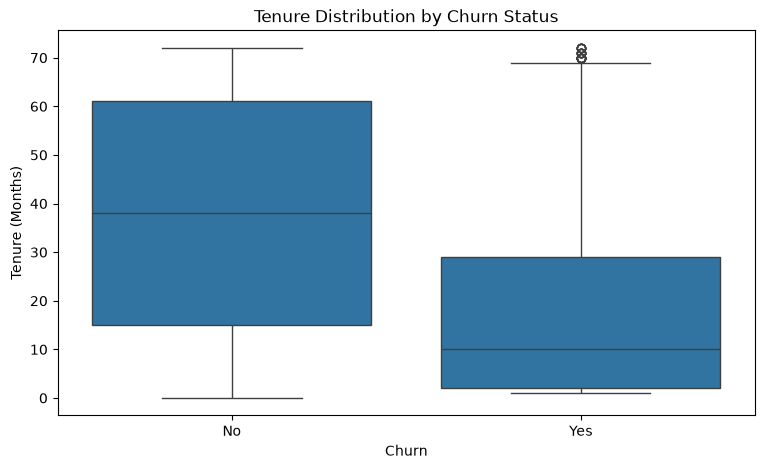

In [8]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [9]:
df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
No,5174,37.569965,38.0,0,72
Yes,1869,17.979133,10.0,1,72


### Tenure Groups

In [11]:
### Tenure Groups

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0-6 Months",
        "7-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

In [12]:
tenure_churn = pd.crosstab(
    df["tenure_group"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn

Churn,No,Yes
tenure_group,,
0-6 Months,47.062795,52.937205
7-12 Months,64.113475,35.886525
13-24 Months,71.289062,28.710938
25-48 Months,79.611041,20.388959
49-72 Months,90.486824,9.513176


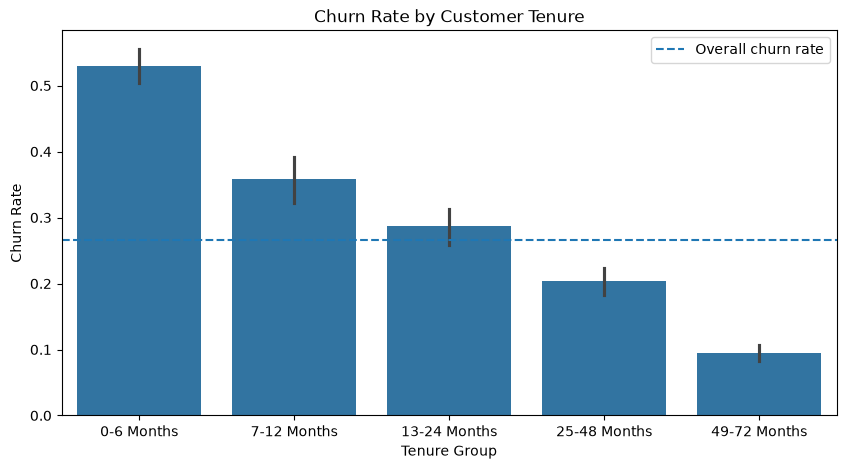

In [13]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="tenure_group",
    y=df["Churn"].eq("Yes").astype(int)
)

plt.axhline(
    churn_rate / 100,
    linestyle="--",
    label="Overall churn rate"
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate")

plt.legend()
plt.show()

In [14]:
print("Contract churn rates:")
print(contract_churn["Yes"].round(2))

print("\nTenure-group churn rates:")
print(tenure_churn["Yes"].round(2))

Contract churn rates:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Yes, dtype: float64

Tenure-group churn rates:
tenure_group
0-6 Months      52.94
7-12 Months     35.89
13-24 Months    28.71
25-48 Months    20.39
49-72 Months     9.51
Name: Yes, dtype: float64


In [15]:
contract_summary = (
    df.groupby("Contract")
      .agg(
          customers=("customerID", "count"),
          churned=("Churn", lambda x: (x == "Yes").sum())
    )
)

contract_summary["churn_rate"] = (
    contract_summary["churned"] /
    contract_summary["customers"] * 100
)

contract_summary.sort_values("churn_rate", ascending=False)

,customers,churned,churn_rate
Contract,,,
Month-to-month,3875,1655,42.709677
One year,1473,166,11.269518
Two year,1695,48,2.831858


### Monthly CHarges & Churn

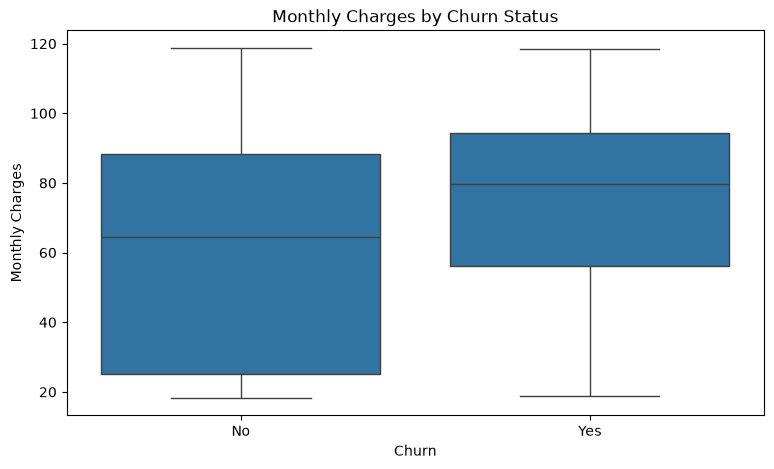

In [16]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [17]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
No,5174,61.265124,64.425,18.25,118.75
Yes,1869,74.441332,79.650,18.85,118.35


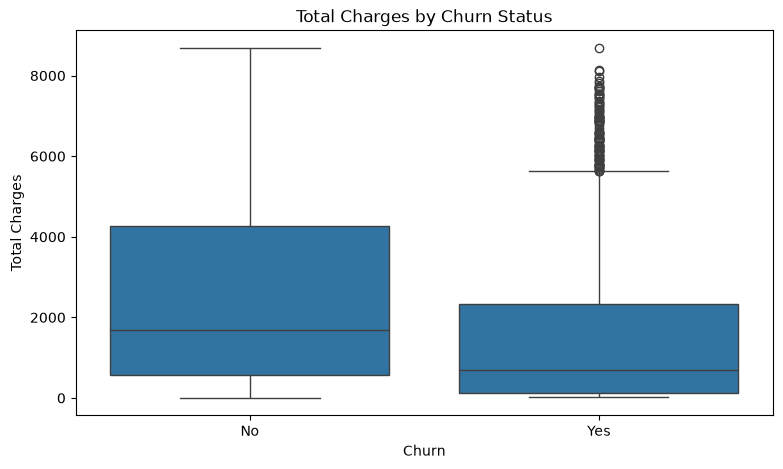

In [18]:
### Total Charges

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

In [19]:
df.groupby("Churn")["TotalCharges"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
No,5174,2549.911442,1679.525,0.00,8672.45
Yes,1869,1531.796094,703.550,18.85,8684.80


## Demographics

In [20]:
def churn_rate_by_column(df, column):
    result = (
        df.groupby(column)["Churn"]
          .apply(lambda x: (x == "Yes").mean() * 100)
          .sort_values(ascending=False)
    )
    
    print(f"\n{column}")
    print(result.round(2))

In [21]:
for col in [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]:
    churn_rate_by_column(df, col)


gender
gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64

SeniorCitizen
SeniorCitizen
1    41.68
0    23.61
Name: Churn, dtype: float64

Partner
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64

Dependents
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64


### Service Level ANalysis

In [22]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for col in service_columns:
    churn_rate_by_column(df, col)


PhoneService
PhoneService
Yes    26.71
No     24.93
Name: Churn, dtype: float64

MultipleLines
MultipleLines
Yes                 28.61
No                  25.04
No phone service    24.93
Name: Churn, dtype: float64

InternetService
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

OnlineSecurity
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64

OnlineBackup
OnlineBackup
No                     39.93
Yes                    21.53
No internet service     7.40
Name: Churn, dtype: float64

DeviceProtection
DeviceProtection
No                     39.13
Yes                    22.50
No internet service     7.40
Name: Churn, dtype: float64

TechSupport
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64

StreamingTV
StreamingTV
No                     33.52
Yes                    30.07

In [23]:
service_results = []

for col in service_columns:
    rates = (
        df.groupby(col)["Churn"]
          .apply(lambda x: (x == "Yes").mean() * 100)
    )
    
    for category, rate in rates.items():
        service_results.append({
            "feature": col,
            "category": category,
            "churn_rate": rate
        })

service_churn = pd.DataFrame(service_results)

service_churn.sort_values(
    "churn_rate",
    ascending=False
)

,feature,category,churn_rate
6,InternetService,Fiber optic,41.892765
8,OnlineSecurity,No,41.766724
17,TechSupport,No,41.635474
11,OnlineBackup,No,39.928756
14,DeviceProtection,No,39.127625
23,StreamingMovies,No,33.680431
20,StreamingTV,No,33.523132
22,StreamingTV,Yes,30.070188
25,StreamingMovies,Yes,29.941435
4,MultipleLines,Yes,28.609896


### Payment & COntract Behaviour

In [24]:
for col in [
    "PaymentMethod",
    "PaperlessBilling"
]:
    churn_rate_by_column(df, col)


PaymentMethod
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

PaperlessBilling
PaperlessBilling
Yes    33.57
No     16.33
Name: Churn, dtype: float64


In [25]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [27]:
### STrongest categorical churn segments

categorical_columns = df.select_dtypes(
    include=["str", "object"]
).columns.tolist()

categorical_columns.remove("customerID")
categorical_columns.remove("Churn")

segment_results = []

for col in categorical_columns:
    rates = (
        df.groupby(col)["Churn"]
          .apply(lambda x: (x == "Yes").mean() * 100)
    )
    
    for category, rate in rates.items():
        segment_results.append({
            "feature": col,
            "category": category,
            "churn_rate": rate,
            "difference_from_baseline": rate - churn_rate
        })

segment_analysis = pd.DataFrame(segment_results)

segment_analysis.sort_values(
    "churn_rate",
    ascending=False
).head(15)

,feature,category,churn_rate,difference_from_baseline
39,PaymentMethod,Electronic check,45.285412,18.748425
32,Contract,Month-to-month,42.709677,16.172690
12,InternetService,Fiber optic,41.892765,15.355778
14,OnlineSecurity,No,41.766724,15.229737
23,TechSupport,No,41.635474,15.098487
17,OnlineBackup,No,39.928756,13.391769
20,DeviceProtection,No,39.127625,12.590638
29,StreamingMovies,No,33.680431,7.143444
36,PaperlessBilling,Yes,33.565092,7.028105
26,StreamingTV,No,33.523132,6.986145


## Feature ENgineering

### Customer Value

In [28]:
df["avg_monthly_value"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    df["MonthlyCharges"]
)

### Number of Subscribed Services

In [31]:
service_binary_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["service_count"] = 0

for col in service_binary_columns:
    df["service_count"] += df[col].eq("Yes").astype(int)


df["service_count"].value_counts().sort_index()

service_count
0      80
1    1701
2    1188
3     965
4     922
5     908
6     676
7     395
8     208
Name: count, dtype: int64

### Support Risk

In [32]:
df["no_tech_support"] = (
    df["TechSupport"] == "No"
).astype(int)

### Security Gap

In [33]:
df["no_online_security"] = (
    df["OnlineSecurity"] == "No"
).astype(int)

### Contract risk

In [34]:
df["contract_risk"] = np.select(
    [
        df["Contract"].eq("Month-to-month"),
        df["Contract"].eq("One year"),
        df["Contract"].eq("Two year")
    ],
    [
        "High",
        "Medium",
        "Low"
    ],
    default="Unknown"
)

## CUstomer Segementation

In [35]:
df["monthly_charge_segment"] = pd.qcut(
    df["MonthlyCharges"],
    q=4,
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

In [36]:
df[
    [
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "avg_monthly_value",
        "service_count",
        "contract_risk",
        "monthly_charge_segment",
        "Churn"
    ]
].head(10)

,tenure,MonthlyCharges,TotalCharges,avg_monthly_value,service_count,contract_risk,monthly_charge_segment,Churn
0,1,29.85,29.85,29.850000,1,High,Low,No
1,34,56.95,1889.50,55.573529,3,Medium,Medium,No
2,2,53.85,108.15,54.075000,3,High,Medium,Yes
3,45,42.30,1840.75,40.905556,3,Medium,Medium,No
4,2,70.70,151.65,75.825000,1,High,High,Yes
5,8,99.65,820.50,102.562500,5,High,Very High,Yes
6,22,89.10,1949.40,88.609091,4,High,High,No
7,10,29.75,301.90,30.190000,1,High,Low,No
8,28,104.80,3046.05,108.787500,6,High,Very High,Yes
9,62,56.15,3487.95,56.257258,3,Medium,Medium,No


### Analyzing new features

In [38]:
### Service Count

service_count_churn = (
    df.groupby("service_count")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print(service_count_churn.round(2))

service_count
0    43.75
1    21.11
2    32.83
3    36.48
4    31.34
5    25.55
6    22.49
7    12.41
8     5.29
Name: Churn, dtype: float64


In [40]:
### Monthly charge segment

charge_segment_churn = (
    df.groupby("monthly_charge_segment", observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print(charge_segment_churn.round(2))

monthly_charge_segment
Low          11.24
Medium       24.58
High         37.51
Very High    32.88
Name: Churn, dtype: float64


In [41]:
### Contract risk

contract_risk_churn = (
    df.groupby("contract_risk")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print(contract_risk_churn.round(2))

contract_risk
High      42.71
Low        2.83
Medium    11.27
Name: Churn, dtype: float64


## Correlations

In [42]:
numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "avg_monthly_value",
    "service_count"
]

df[numeric_cols].corr()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,avg_monthly_value,service_count
SeniorCitizen,1.000000,0.016567,0.220173,0.103006,0.217917,0.095946
tenure,0.016567,1.000000,0.247900,0.826178,0.247234,0.523600
MonthlyCharges,0.220173,0.247900,1.000000,0.651174,0.996244,0.802322
TotalCharges,0.103006,0.826178,0.651174,1.000000,0.651025,0.795854
avg_monthly_value,0.217917,0.247234,0.996244,0.651025,1.000000,0.800366
service_count,0.095946,0.523600,0.802322,0.795854,0.800366,1.000000


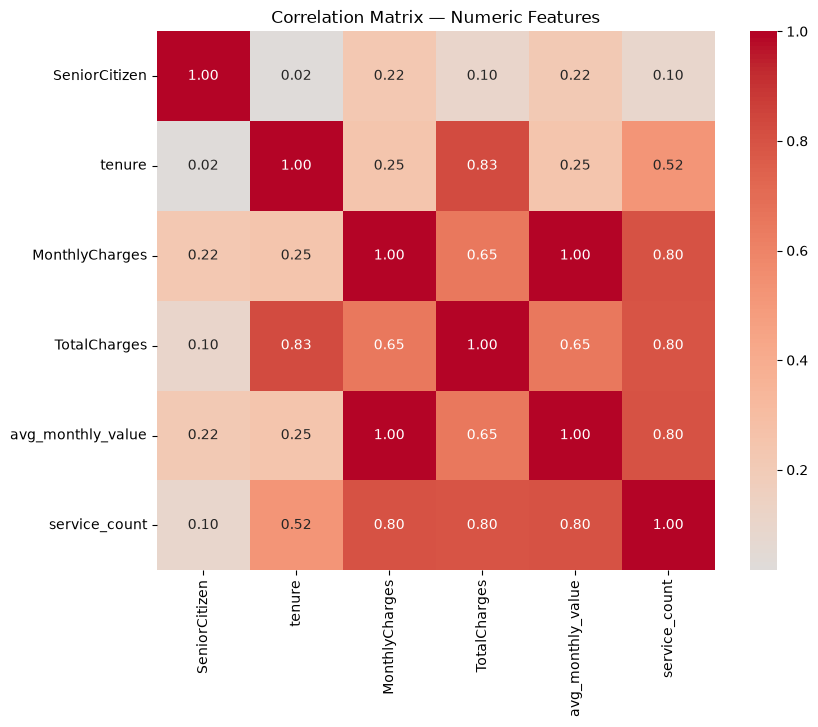

In [43]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix — Numeric Features")
plt.show()

## STatistical Validation

In [44]:
from scipy.stats import chi2_contingency

In [46]:
categorical_test_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]


chi_results = []

for col in categorical_test_columns:
    contingency_table = pd.crosstab(
        df[col],
        df["Churn"]
    )
    
    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )
    
    chi_results.append({
        "feature": col,
        "chi2": chi2,
        "p_value": p_value
    })

chi_results = pd.DataFrame(chi_results)

chi_results.sort_values("p_value")

,feature,chi2,p_value
13,Contract,1184.596572,5.863038e-258
7,OnlineSecurity,849.998968,2.661150e-185
10,TechSupport,828.197068,1.443084e-180
6,InternetService,732.309590,9.571788e-160
15,PaymentMethod,648.142327,3.682355e-140
8,OnlineBackup,601.812790,2.079759e-131
9,DeviceProtection,558.419369,5.505219e-122
12,StreamingMovies,375.661479,2.667757e-82
11,StreamingTV,374.203943,5.528994e-82
14,PaperlessBilling,258.277649,4.073355e-58


## Numerical Feature Testing

In [47]:
from scipy.stats import mannwhitneyu

numeric_test_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "avg_monthly_value",
    "service_count"
]

numeric_results = []

for col in numeric_test_columns:
    churned = df.loc[df["Churn"] == "Yes", col]
    retained = df.loc[df["Churn"] == "No", col]
    
    statistic, p_value = mannwhitneyu(
        churned,
        retained,
        alternative="two-sided"
    )
    
    numeric_results.append({
        "feature": col,
        "U_statistic": statistic,
        "p_value": p_value
    })

numeric_results = pd.DataFrame(numeric_results)

numeric_results.sort_values("p_value")

,feature,U_statistic,p_value
0,tenure,2515538.0,2.419636e-208
2,TotalCharges,3381224.0,5.685034e-83
3,avg_monthly_value,6005360.0,2.087423e-54
1,MonthlyCharges,6003125.5,3.311628e-54
4,service_count,4561192.5,2.282293e-04
